In [ ]:
import pandas as pd

In [ ]:
import pandas as np

In [18]:
df = pd.read_csv("/content/airlines_flights_data.csv")
df

,index,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1.0,5953.0
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1.0,5953.0
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1.0,5956.0
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1.0,5955.0
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1.0,5955.0
...,...,...,...,...,...,...,...,...,...,...,...,...
153003,153003,Indigo,6E-6737,Hyderabad,Early_Morning,zero,Morning,Delhi,Economy,2.25,7.0,6868.0
153004,153004,Indigo,6E-7076,Hyderabad,Afternoon,one,Night,Delhi,Economy,8.67,7.0,9073.0
153005,153005,Indigo,6E-6467,Hyderabad,Afternoon,one,Night,Delhi,Economy,8.75,7.0,9073.0
153006,153006,Indigo,6E-913,Hyderabad,Morning,one,Night,Delhi,Economy,8.83,7.0,9441.0


In [19]:
df.tail()


,index,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
153003,153003,Indigo,6E-6737,Hyderabad,Early_Morning,zero,Morning,Delhi,Economy,2.25,7.0,6868.0
153004,153004,Indigo,6E-7076,Hyderabad,Afternoon,one,Night,Delhi,Economy,8.67,7.0,9073.0
153005,153005,Indigo,6E-6467,Hyderabad,Afternoon,one,Night,Delhi,Economy,8.75,7.0,9073.0
153006,153006,Indigo,6E-913,Hyderabad,Morning,one,Night,Delhi,Economy,8.83,7.0,9441.0
153007,153007,Vistara,UK-878,Hyderabad,Afternoon,on,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
df.describe()

,index,duration,days_left,price
count,153008.000000,153007.000000,153007.000000,153007.000000
mean,76503.500000,11.452514,25.968315,6641.013019
std,44169.749331,7.196894,13.609077,3704.812939
min,0.000000,0.830000,1.000000,1603.000000
25%,38251.750000,6.170000,15.000000,4173.500000
50%,76503.500000,10.170000,26.000000,5915.000000
75%,114755.250000,15.170000,38.000000,7781.000000
max,153007.000000,47.750000,49.000000,40354.000000


In [21]:
df.dtypes

,0
index,int64
airline,object
flight,object
source_city,object
departure_time,object
stops,object
arrival_time,object
destination_city,object
class,object
duration,float64


In [29]:
# Separate numeric and categorical columns
numeric_columns = df.select_dtypes(include=['int64','float64',]).columns.tolist()
catergorical_columns = df.select_dtypes(include=['object']).columns.tolist()

In [30]:
print(numeric_columns)
print(catergorical_columns)

['index', 'airline', 'duration', 'days_left', 'price']
['flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class']


In [26]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Convert duration to numeric, replacing non-numeric values with NaN
df['duration'] = pd.to_numeric(df['duration'], errors='coerce')

# Fill any missing values in duration with the median value
df['duration'] = df['duration'].fillna(df['duration'].median())

# Select numeric columns
X = df[['duration', 'days_left', 'price']]

# Rescale data
scaler = MinMaxScaler()
rescaled_data = scaler.fit_transform(X)

# Display result
print(rescaled_data)

[[0.02855925 0.         0.11225517]
 [0.03196931 0.         0.11225517]
 [0.02855925 0.         0.11233258]
 ...
 [0.16879795 0.125      0.19276922]
 [0.17050298 0.125      0.20226575]
 [0.19906223        nan        nan]]


In [27]:
from sklearn.preprocessing import LabelEncoder

# Create LabelEncoder object
encoder = LabelEncoder()

# Encode categorical column
df['airline'] = encoder.fit_transform(df['airline'])

# Display encoded data
print(df[['airline']].head())

   airline
0        4
1        4
2        0
3        5
4        5


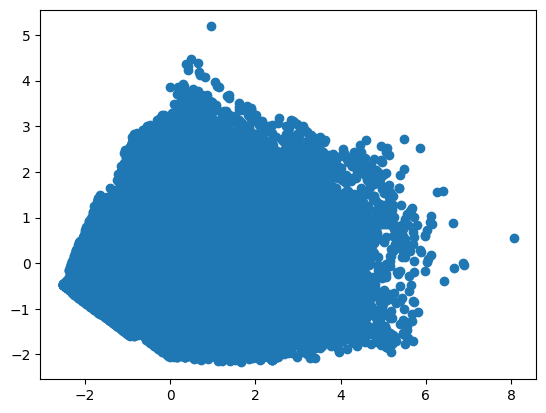

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Select numeric features
X = df[['duration', 'days_left', 'price']]

# Handle missing values
X = X.fillna(X.mean())

# Standardize data
X_scaled = StandardScaler().fit_transform(X)

# Apply PCA
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)

# Plot
plt.scatter(principal_components[:, 0], principal_components[:, 1])